In [1]:
import numpy as np
import matplotlib.pyplot as plt
import batman
import emcee
import corner

# load K2 data
data = np.loadtxt(
    "../data/apjladf06ft3_mrt.txt",
    skiprows=15
)

t = data[:, 0] + 2454833  # offset to full BJD
flux = data[:, 2]

# published mid-transit time from Venner et al. (2026)
t0_published = 2458055.0969

# only use the region around the transit
mask = np.abs(t - t0_published) < 0.8

t_transit = t[mask]
flux_transit = flux[mask]

In [2]:
# gravitational constant in SI units
G = 6.67430e-11

# standard deviation of the out-of-transit K2 light curve
sigma_flux = 32e-6

# stellar-density prior from Venner et al. (2026):
# log10(rho_star / (g cm^-3)) = 0.462 +/- 0.041
logrho_mean = 0.462
logrho_sigma = 0.041

# limb-darkening priors in the Kepler band
u1_mean = 0.60
u1_sigma = 0.07

u2_mean = 0.12
u2_sigma = 0.07

# maximum eccentricity for this first broad-prior experiment
e_max = 0.8

In [4]:
def a_over_rstar(period, rho_star):
    """
    Calculate a/R_star using Kepler's third law.

    period   : orbital period in days
    rho_star : stellar density in g/cm^3
    """

    # days -> seconds
    period_seconds = period * 24 * 60 * 60

    # g/cm^3 -> kg/m^3
    rho_si = rho_star * 1000

    return (
        G * rho_si * period_seconds**2
        / (3 * np.pi)
    )**(1/3)

print(a_over_rstar(355, 2.90))

268.33187277032084


In [6]:
def eccentricity_from_hk(h, k):
    """
    Convert h = sqrt(e) cos(omega) and
    k = sqrt(e) sin(omega) back to e and omega.
    """

    e = h**2 + k**2

    # arctan2 gives omega between -pi and pi
    omega = np.degrees(np.arctan2(k, h))

    # batman prefers angles between 0 and 360 degrees
    omega = omega % 360

    return e, omega


print(eccentricity_from_hk(0.0, np.sqrt(0.1)))

(np.float64(0.1), np.float64(90.0))


In [7]:
# starting parameters only needed to initialise batman
batman_params = batman.TransitParams()

batman_params.t0 = t0_published
batman_params.per = 355.0
batman_params.rp = 0.01368
batman_params.a = 270.0
batman_params.inc = 90.0

batman_params.ecc = 0.0
batman_params.w = 90.0

batman_params.u = [0.60, 0.12]
batman_params.limb_dark = "quadratic"

# same 29.4-min K2 exposure and 10x supersampling as before
batman_model = batman.TransitModel(
    batman_params,
    t_transit,
    supersample_factor=10,
    exp_time=29.4 / (24 * 60)
)

In [8]:
def transit_model(theta):
    """
    Transit model with eccentricity.

    theta =
    (period, b, rp, t0, rho_star, u1, u2, h, k)
    """

    period, b, rp, t0, rho_star, u1, u2, h, k = theta

    # convert h and k back to e and omega
    e, omega = eccentricity_from_hk(h, k)

    # calculate a/Rstar from period and stellar density
    a_Rstar = a_over_rstar(period, rho_star)

    omega_rad = np.radians(omega)

    # For an eccentric orbit:
    #
    # b = (a/Rstar) cos(i) (1-e^2)/(1+e sin(omega))
    #
    # therefore:
    cos_i = (
        b / a_Rstar
        * (1 + e * np.sin(omega_rad))
        / (1 - e**2)
    )

    # reject geometrically impossible solutions
    if cos_i < 0 or cos_i > 1:
        return None

    inclination = np.degrees(np.arccos(cos_i))

    # update batman parameters
    batman_params.t0 = t0
    batman_params.per = period
    batman_params.rp = rp
    batman_params.a = a_Rstar
    batman_params.inc = inclination

    batman_params.ecc = e
    batman_params.w = omega

    batman_params.u = [u1, u2]

    return batman_model.light_curve(batman_params)

In [9]:
#prior

def log_prior(theta):
    """
    Priors for the first eccentric model.

    For now we use a broad uniform eccentricity prior:
    0 <= e < 0.8.

    The other priors are kept the same as in the circular model
    so that we can make a fair comparison.
    """

    period, b, rp, t0, rho_star, u1, u2, h, k = theta

    # convert h,k -> eccentricity and omega
    e, omega = eccentricity_from_hk(h, k)


    # --------------------------------------------------
    # Basic parameter limits
    # --------------------------------------------------

    if not 64 < period < 2000:
        return -np.inf

    if not 0 <= b < 1 + rp:
        return -np.inf

    if not 0.005 < rp < 0.03:
        return -np.inf

    if not t0_published - 0.1 < t0 < t0_published + 0.1:
        return -np.inf

    if rho_star <= 0:
        return -np.inf


    # --------------------------------------------------
    # Eccentricity prior
    # --------------------------------------------------

    # Since e = h^2 + k^2, this restricts h and k to a disk.
    # Uniform sampling inside this disk corresponds to
    # uniform e and uniform omega.
    if not 0 <= e < e_max:
        return -np.inf


    # --------------------------------------------------
    # Physical limb-darkening conditions
    # --------------------------------------------------

    if not (
        u1 > 0
        and u1 + u2 < 1
        and u1 + 2*u2 > 0
    ):
        return -np.inf


    # --------------------------------------------------
    # Orbital geometry
    # --------------------------------------------------

    a_Rstar = a_over_rstar(period, rho_star)

    # Reject solutions where the planet's periastron
    # would actually be inside the star.
    if a_Rstar * (1 - e) <= 1 + rp:
        return -np.inf

    omega_rad = np.radians(omega)

    cos_i = (
        b / a_Rstar
        * (1 + e * np.sin(omega_rad))
        / (1 - e**2)
    )

    if cos_i < 0 or cos_i > 1:
        return -np.inf


    lp = 0.0


    # --------------------------------------------------
    # Same period prior as in notebook 03
    # --------------------------------------------------

    # log-uniform period prior
    lp += -np.log(period)

    # approximation of the Kipping single-transit prior
    lp += -(5/3) * np.log(period)


    # --------------------------------------------------
    # Radius-ratio prior
    # --------------------------------------------------

    lp += -np.log(rp)


    # --------------------------------------------------
    # Stellar-density prior
    # --------------------------------------------------

    lp += -np.log(rho_star)

    log_rho = np.log10(rho_star)

    lp += -0.5 * (
        (log_rho - logrho_mean) / logrho_sigma
    )**2


    # --------------------------------------------------
    # Limb-darkening priors
    # --------------------------------------------------

    lp += -0.5 * ((u1 - u1_mean) / u1_sigma)**2
    lp += -0.5 * ((u2 - u2_mean) / u2_sigma)**2


    # No extra eccentricity term is needed here.
    # A uniform distribution in the h-k disk gives us
    # a uniform prior in e and omega.

    return lp

In [10]:
#likelihood

def log_likelihood(theta):
    """
    Gaussian likelihood comparing the observed K2 flux
    with the eccentric transit model.
    """

    model_flux = transit_model(theta)

    if model_flux is None:
        return -np.inf

    if not np.all(np.isfinite(model_flux)):
        return -np.inf

    residuals = flux_transit - model_flux

    return -0.5 * np.sum(
        residuals**2 / sigma_flux**2
        + np.log(2 * np.pi * sigma_flux**2)
    )

In [11]:
#posterior

def log_probability(theta):
    """
    log posterior = log prior + log likelihood
    """

    lp = log_prior(theta)

    if not np.isfinite(lp):
        return -np.inf

    return lp + log_likelihood(theta)

In [12]:
#small test run to check that the code works

e_test = 0.05
omega_test = 90.0

h_test = np.sqrt(e_test) * np.cos(np.radians(omega_test))
k_test = np.sqrt(e_test) * np.sin(np.radians(omega_test))

theta_test = (
    355.0,          # period [days]
    0.3,            # impact parameter
    0.01368,        # Rp/Rstar
    t0_published,   # mid-transit time
    2.90,           # stellar density
    0.60,           # u1
    0.12,           # u2
    h_test,
    k_test
)

print("e, omega:", eccentricity_from_hk(h_test, k_test))
print("log prior:", log_prior(theta_test))
print("log likelihood:", log_likelihood(theta_test))
print("log posterior:", log_probability(theta_test))

e, omega: (np.float64(0.049999999999999996), np.float64(90.0))
log prior: -12.431918257644067
log likelihood: 597.20530085851
log posterior: 584.773382600866


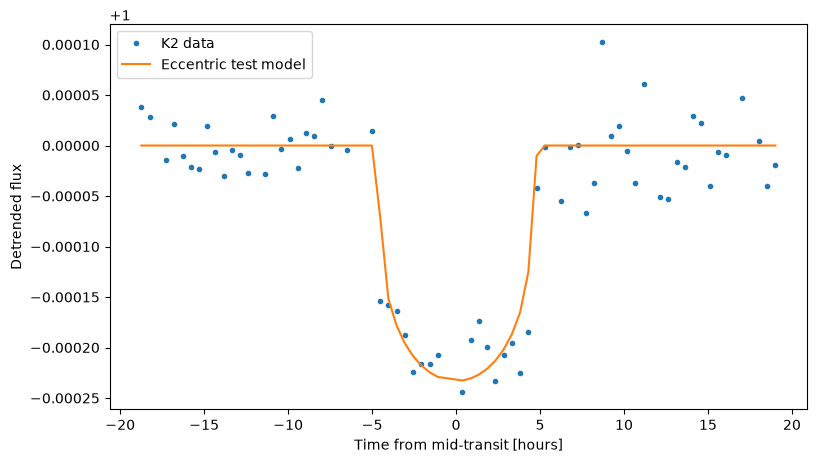

In [13]:
model_test = transit_model(theta_test)

plt.figure(figsize=(9, 5))

plt.plot(
    (t_transit - t0_published) * 24,
    flux_transit,
    ".",
    label="K2 data"
)

plt.plot(
    (t_transit - t0_published) * 24,
    model_test,
    label="Eccentric test model"
)

plt.xlabel("Time from mid-transit [hours]")
plt.ylabel("Detrended flux")
plt.legend()
plt.show()

In [14]:
#mcmc

ndim = 9
nwalkers = 60

labels = [
    "Period [d]",
    "b",
    "Rp/Rstar",
    "t0 [BJD]",
    "rho_star",
    "u1",
    "u2",
    "h",
    "k"
]

initial = np.array([
    355.0,
    0.3,
    0.01368,
    t0_published,
    2.90,
    0.60,
    0.12,
    h_test,
    k_test
])

spread = np.array([
    30.0,      # period
    0.15,      # b
    0.0005,    # Rp/Rstar
    0.005,     # t0
    0.10,      # rho_star
    0.03,      # u1
    0.03,      # u2
    0.08,      # h
    0.08       # k
])

rng = np.random.default_rng(42)

In [16]:
pos = []
#generating only valid starting walkers
while len(pos) < nwalkers:

    candidate = initial + spread * rng.normal(size=ndim)

    if np.isfinite(log_probability(candidate)):
        pos.append(candidate)

pos = np.array(pos)

print(pos.shape)

(60, 9)


In [17]:
#mcmc run

sampler = emcee.EnsembleSampler(
    nwalkers,
    ndim,
    log_probability
)

sampler.run_mcmc(
    pos,
    10000,
    progress=True
)

You must install the tqdm library to use progress indicators with emcee


State([[ 2.26133985e+02  2.39486006e-01  1.36826498e-02  2.45805510e+06
   2.82935890e+00  5.15142913e-01  8.88637036e-02  7.03258372e-01
  -3.85562910e-01]
 [ 2.31539424e+02  1.35607546e-01  1.33551659e-02  2.45805510e+06
   3.01085900e+00  5.54751947e-01  2.29006373e-02  3.80446901e-01
  -3.03479017e-01]
 [ 8.24590179e+01  3.55269323e-01  1.36562531e-02  2.45805509e+06
   2.53543099e+00  4.58877403e-01  9.39825472e-02 -3.51254270e-01
  -6.47157902e-01]
 [ 3.66596337e+02  5.90315080e-01  1.41556682e-02  2.45805509e+06
   3.57844101e+00  6.00318008e-01 -8.25439364e-03  6.26486658e-01
  -4.52225033e-01]
 [ 2.14324840e+02  4.27941007e-01  1.38881380e-02  2.45805509e+06
   2.70250436e+00  5.64117549e-01  8.01780595e-02  4.93769861e-01
  -3.98041250e-01]
 [ 2.72055250e+02  6.97746742e-02  1.34826399e-02  2.45805510e+06
   2.79145523e+00  6.21005620e-01  1.58453497e-01  1.38562056e-01
  -1.97125958e-01]
 [ 1.26137160e+02  2.04354983e-01  1.34281655e-02  2.45805510e+06
   2.70620018e+00  5.8

In [18]:
print(sampler.get_chain().shape)

(10000, 60, 9)


In [19]:
#diagnostics

print(
    "Mean acceptance fraction:",
    np.mean(sampler.acceptance_fraction)
)

tau = sampler.get_autocorr_time(tol=0)

print()

for label, value in zip(labels, tau):
    print(f"{label}: tau = {value:.1f}")

print()
print("Chain length / tau:")

for label, value in zip(labels, tau):
    print(
        f"{label}: "
        f"{sampler.iteration / value:.1f}"
    )

Mean acceptance fraction: 0.21969666666666668

Period [d]: tau = 473.9
b: tau = 508.7
Rp/Rstar: tau = 468.3
t0 [BJD]: tau = 323.2
rho_star: tau = 300.9
u1: tau = 269.9
u2: tau = 259.1
h: tau = 389.8
k: tau = 433.0

Chain length / tau:
Period [d]: 21.1
b: 19.7
Rp/Rstar: 21.4
t0 [BJD]: 30.9
rho_star: 33.2
u1: 37.0
u2: 38.6
h: 25.7
k: 23.1


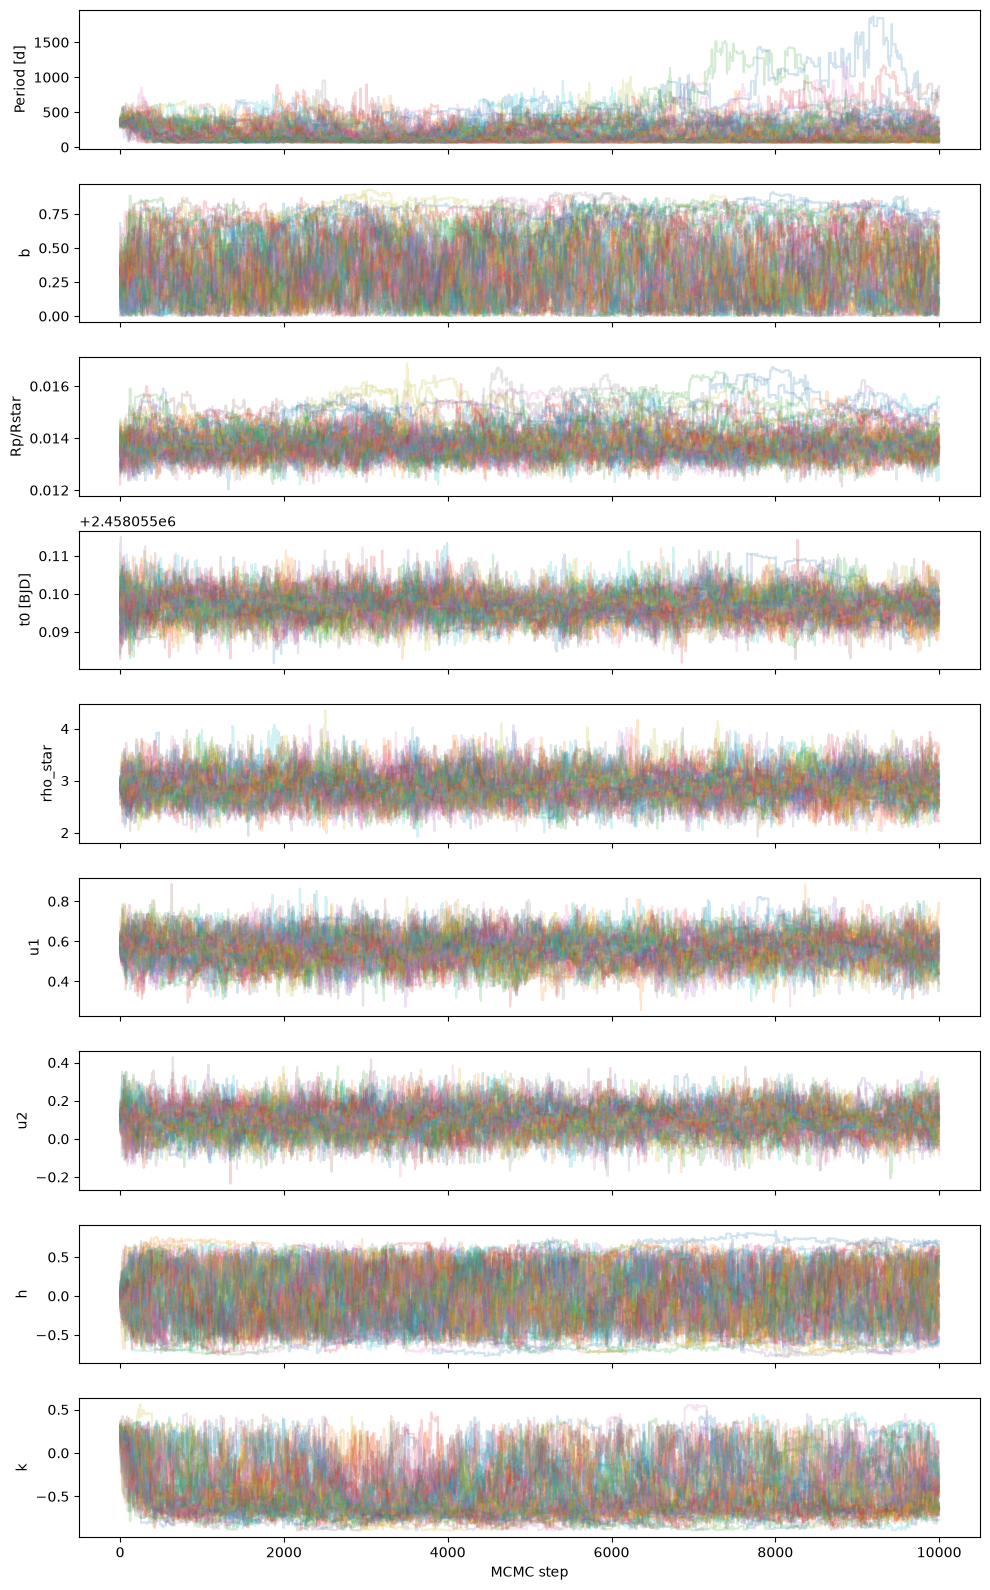

In [20]:
chain = sampler.get_chain()

fig, axes = plt.subplots(
    ndim,
    figsize=(10, 16),
    sharex=True
)

for i in range(ndim):

    axes[i].plot(
        chain[:, :, i],
        alpha=0.20
    )

    axes[i].set_ylabel(labels[i])

axes[-1].set_xlabel("MCMC step")

plt.tight_layout()
plt.show()

In [21]:
#more steps

sampler.run_mcmc(
    None,
    10000,
    progress=True
)

You must install the tqdm library to use progress indicators with emcee


State([[ 9.71698292e+01  2.24620940e-01  1.34305799e-02  2.45805509e+06
   3.05359994e+00  5.84300329e-01 -5.33993771e-03 -5.16376997e-01
  -6.02992375e-01]
 [ 2.31255289e+02  1.54934809e-01  1.40807018e-02  2.45805510e+06
   2.24016766e+00  4.62179409e-01  1.03961905e-01 -7.20743593e-01
  -2.35104413e-01]
 [ 6.64809504e+01  1.97221066e-02  1.32010751e-02  2.45805510e+06
   2.46161163e+00  6.63427414e-01  2.23827464e-01 -1.14681035e-01
  -6.62474585e-01]
 [ 1.51986225e+02  6.70527777e-01  1.48232411e-02  2.45805509e+06
   2.61640268e+00  5.39567835e-01  9.58213021e-02 -1.45314126e-01
  -6.65122108e-01]
 [ 1.37721629e+02  2.72965725e-01  1.39641112e-02  2.45805509e+06
   3.21634540e+00  4.84213533e-01  1.17641504e-01  1.22712134e-01
  -5.44217152e-01]
 [ 2.03065112e+02  4.91814224e-01  1.42566050e-02  2.45805510e+06
   2.50295673e+00  5.26426489e-01  8.10339555e-02 -2.84868829e-01
  -4.29537422e-01]
 [ 9.32530724e+01  3.95283408e-01  1.34965788e-02  2.45805510e+06
   3.03535397e+00  6.2

In [22]:
tau = sampler.get_autocorr_time(tol=0)

for label, value in zip(labels, tau):
    print(
        f"{label}: tau = {value:.1f}, "
        f"N/tau = {sampler.iteration/value:.1f}"
    )

Period [d]: tau = 701.4, N/tau = 28.5
b: tau = 731.2, N/tau = 27.4
Rp/Rstar: tau = 734.3, N/tau = 27.2
t0 [BJD]: tau = 347.2, N/tau = 57.6
rho_star: tau = 331.9, N/tau = 60.3
u1: tau = 374.2, N/tau = 53.5
u2: tau = 331.7, N/tau = 60.3
h: tau = 506.4, N/tau = 39.5
k: tau = 598.6, N/tau = 33.4


In [23]:
#stability check

chain = sampler.get_chain()

N = sampler.iteration

# ignore the first quarter and compare two later pieces
start = N // 4
middle = (start + N) // 2

samples_earlier = chain[start:middle].reshape(-1, ndim)
samples_later = chain[middle:N].reshape(-1, ndim)

for i, label in enumerate(labels):

    q_earlier = np.percentile(
        samples_earlier[:, i],
        [16, 50, 84]
    )

    q_later = np.percentile(
        samples_later[:, i],
        [16, 50, 84]
    )

    print(label)
    print("  earlier:", q_earlier)
    print("  later:  ", q_later)

Period [d]
  earlier: [ 80.91160534 155.05813113 371.01284776]
  later:   [ 79.85393989 141.2231548  315.42973568]
b
  earlier: [0.10275345 0.33883184 0.64877952]
  later:   [0.10971263 0.33804934 0.62809156]
Rp/Rstar
  earlier: [0.01331633 0.01375308 0.01446885]
  later:   [0.01331628 0.01374583 0.01441851]
t0 [BJD]
  earlier: [2458055.09359917 2458055.09684505 2458055.10011937]
  later:   [2458055.09362172 2458055.09682414 2458055.09998654]
rho_star
  earlier: [2.63280053 2.87711951 3.15407785]
  later:   [2.62130801 2.86978897 3.15437538]
u1
  earlier: [0.4926157  0.56116174 0.62630302]
  later:   [0.48981173 0.55580221 0.62280307]
u2
  earlier: [0.02921902 0.09470213 0.16338111]
  later:   [0.02809234 0.09606792 0.16711159]
h
  earlier: [-0.43489763 -0.01343472  0.41020062]
  later:   [-4.12887377e-01  8.62108824e-06  4.01575346e-01]
k
  earlier: [-0.70313511 -0.54858477 -0.16914402]
  later:   [-0.71584353 -0.58218892 -0.18990406]


In [24]:
#posterior

burnin = sampler.iteration // 2
thin = 100

flat_samples = sampler.get_chain(
    discard=burnin,
    thin=thin,
    flat=True
)

print("Total chain length:", sampler.iteration)
print("Burn-in:", burnin)
print("Posterior samples:", len(flat_samples))

Total chain length: 20000
Burn-in: 10000
Posterior samples: 6000


In [25]:
np.save(
    "../data/eccentric_uniform_posterior.npy",
    flat_samples
)

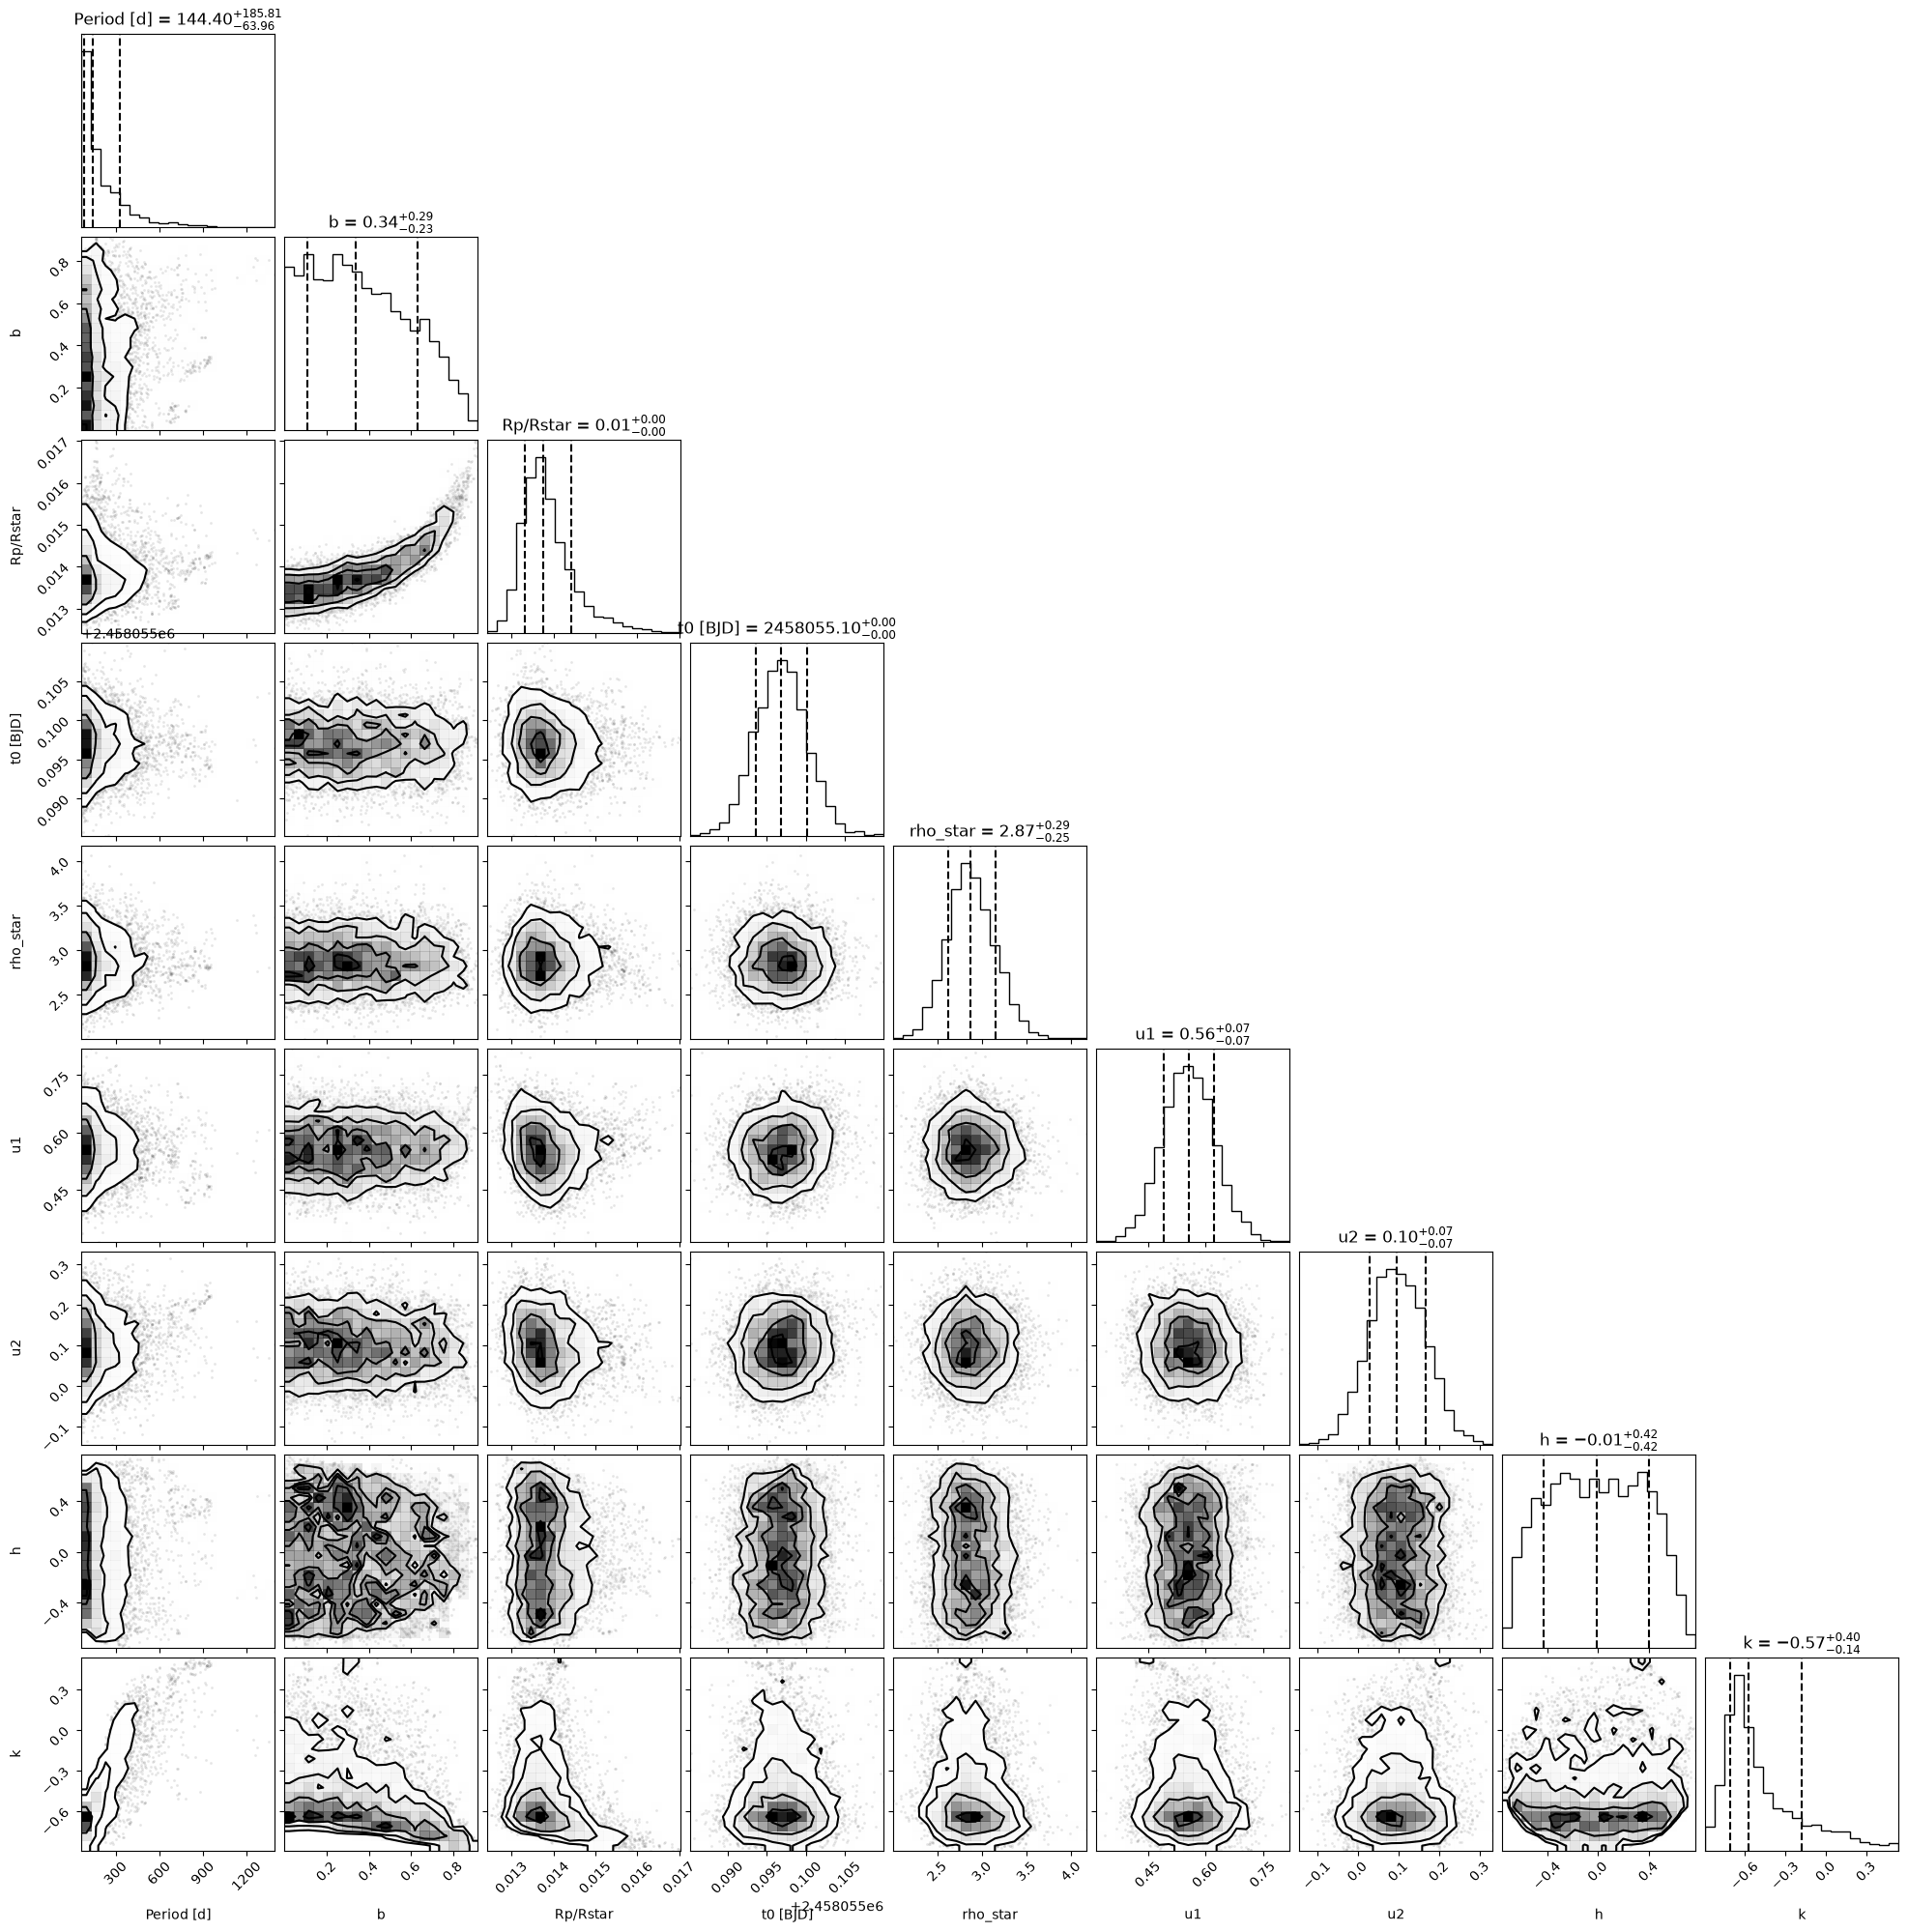

In [26]:
#corner plot of sampled parameters

fig = corner.corner(
    flat_samples,
    labels=labels,
    show_titles=True,
    quantiles=[0.16, 0.50, 0.84]
)

plt.show()

In [27]:
h_samples = flat_samples[:, 7]
k_samples = flat_samples[:, 8]

e_samples = h_samples**2 + k_samples**2

omega_samples = (
    np.degrees(
        np.arctan2(k_samples, h_samples)
    )
    % 360
)

print("Median eccentricity:", np.median(e_samples))

Median eccentricity: 0.4673055047214413


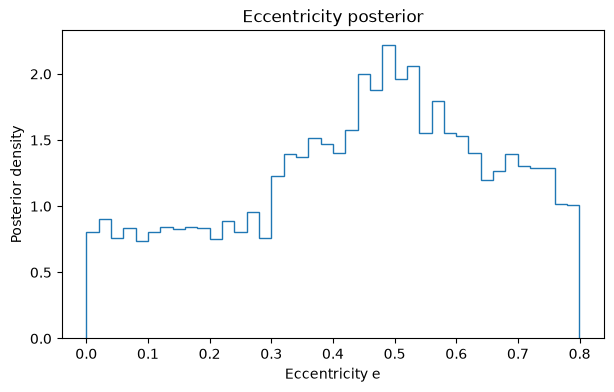

In [28]:
plt.figure(figsize=(7, 4))

plt.hist(
    e_samples,
    bins=40,
    density=True,
    histtype="step"
)

plt.xlabel("Eccentricity e")
plt.ylabel("Posterior density")
plt.title("Eccentricity posterior")

plt.show()

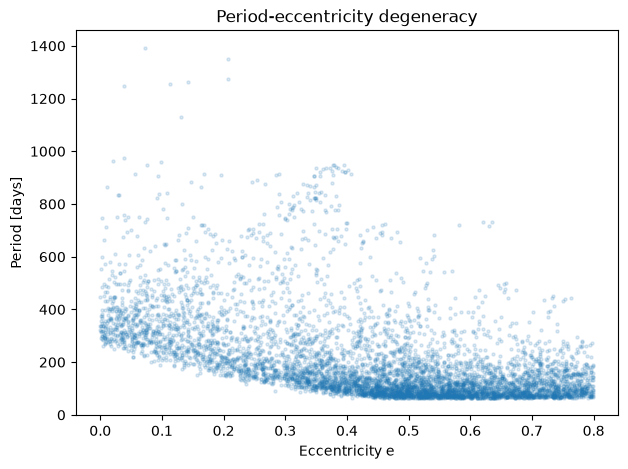

In [29]:
period_samples = flat_samples[:, 0]

plt.figure(figsize=(7, 5))

plt.scatter(
    e_samples,
    period_samples,
    s=5,
    alpha=0.15
)

plt.xlabel("Eccentricity e")
plt.ylabel("Period [days]")
plt.title("Period-eccentricity degeneracy")

plt.show()

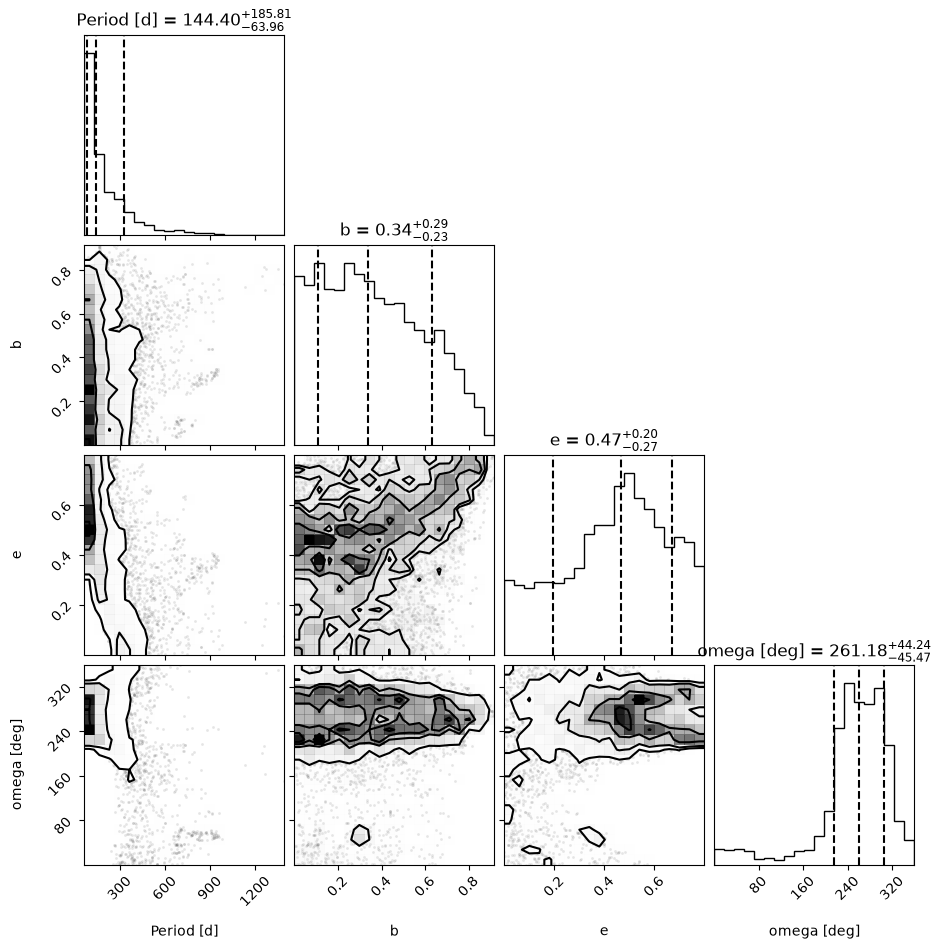

In [30]:
science_samples = np.column_stack([
    flat_samples[:, 0],   # period
    flat_samples[:, 1],   # b
    e_samples,
    omega_samples
])

science_labels = [
    "Period [d]",
    "b",
    "e",
    "omega [deg]"
]

fig = corner.corner(
    science_samples,
    labels=science_labels,
    show_titles=True,
    quantiles=[0.16, 0.50, 0.84]
)

plt.show()

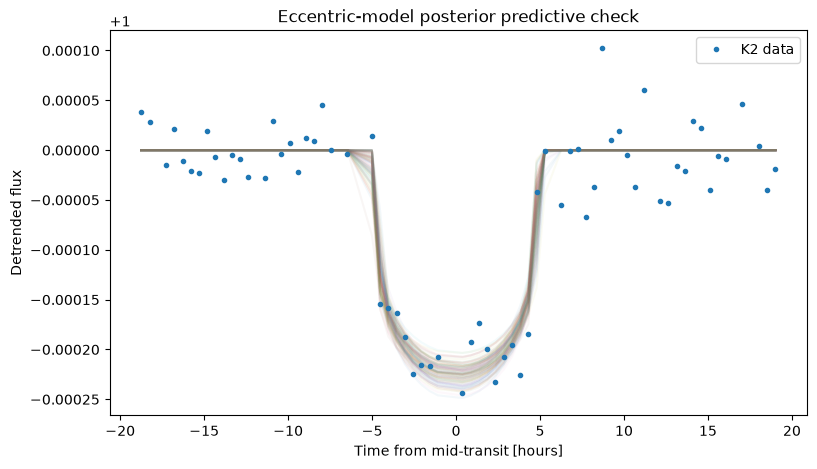

In [31]:
#posterior predictive check

rng = np.random.default_rng(1)

n_models = min(100, len(flat_samples))

indices = rng.choice(
    len(flat_samples),
    size=n_models,
    replace=False
)

plt.figure(figsize=(9, 5))

# draw posterior models first
for index in indices:

    model_flux = transit_model(
        flat_samples[index]
    )

    plt.plot(
        (t_transit - t0_published) * 24,
        model_flux,
        alpha=0.05
    )

# observations on top
plt.plot(
    (t_transit - t0_published) * 24,
    flux_transit,
    ".",
    label="K2 data"
)

plt.xlabel("Time from mid-transit [hours]")
plt.ylabel("Detrended flux")
plt.title("Eccentric-model posterior predictive check")
plt.legend()

plt.show()

In [32]:
#numerical results

for i, label in enumerate(labels[:7]):

    q16, q50, q84 = np.percentile(
        flat_samples[:, i],
        [16, 50, 84]
    )

    print(
        f"{label}: "
        f"{q50:.5f} "
        f"-{q50-q16:.5f} "
        f"+{q84-q50:.5f}"
    )

Period [d]: 144.39590 -63.95508 +185.81350
b: 0.33991 -0.23058 +0.29345
Rp/Rstar: 0.01375 -0.00044 +0.00067
t0 [BJD]: 2458055.09684 -0.00329 +0.00325
rho_star: 2.86803 -0.24625 +0.28616
u1: 0.55588 -0.06608 +0.06680
u2: 0.09631 -0.06681 +0.07154


In [33]:
e16, e50, e84 = np.percentile(
    e_samples,
    [16, 50, 84]
)

print(
    f"e: "
    f"{e50:.3f} "
    f"-{e50-e16:.3f} "
    f"+{e84-e50:.3f}"
)

e: 0.467 -0.272 +0.202


In [34]:
np.save("../data/circular_posterior.npy", flat_samples)

In [35]:
circular_samples = np.load(
    "../data/circular_posterior.npy"
)

period_circular = circular_samples[:, 0]
period_eccentric = flat_samples[:, 0]

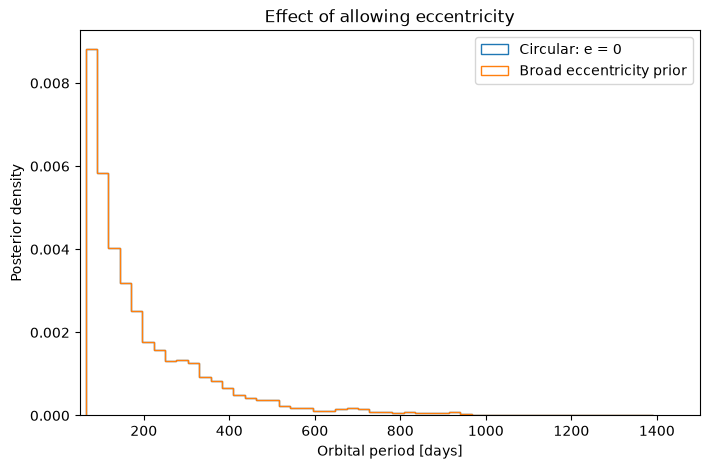

In [36]:
plt.figure(figsize=(8, 5))

plt.hist(
    period_circular,
    bins=50,
    density=True,
    histtype="step",
    label="Circular: e = 0"
)

plt.hist(
    period_eccentric,
    bins=50,
    density=True,
    histtype="step",
    label="Broad eccentricity prior"
)

plt.xlabel("Orbital period [days]")
plt.ylabel("Posterior density")
plt.title("Effect of allowing eccentricity")

plt.xlim(50, 1500)

plt.legend()
plt.show()

In [37]:
def summary(samples):

    q16, q50, q84 = np.percentile(
        samples,
        [16, 50, 84]
    )

    return q50, q50-q16, q84-q50


circ = summary(period_circular)
ecc = summary(period_eccentric)

print(
    f"Circular: "
    f"{circ[0]:.1f} "
    f"-{circ[1]:.1f} "
    f"+{circ[2]:.1f} days"
)

print(
    f"Eccentric: "
    f"{ecc[0]:.1f} "
    f"-{ecc[1]:.1f} "
    f"+{ecc[2]:.1f} days"
)

Circular: 144.4 -64.0 +185.8 days
Eccentric: 144.4 -64.0 +185.8 days


In [38]:
#add more steps

sampler.run_mcmc(
    None,
    10000,
    progress=True
)

You must install the tqdm library to use progress indicators with emcee


State([[ 3.96483714e+02  1.02001294e-01  1.36066630e-02  2.45805510e+06
   2.96957495e+00  6.32048338e-01  1.27797522e-01 -3.58162767e-01
   2.15575403e-01]
 [ 1.43461465e+02  5.19206302e-01  1.41091985e-02  2.45805510e+06
   2.98757316e+00  5.82918476e-01  3.39632448e-02 -1.45837575e-01
  -6.22801388e-01]
 [ 3.53181671e+02  2.60382232e-01  1.37592982e-02  2.45805509e+06
   3.15655696e+00  5.69567900e-01  1.05708898e-01  2.16425456e-01
   8.70187151e-03]
 [ 4.62767201e+02  3.68917942e-01  1.39424305e-02  2.45805510e+06
   2.73419618e+00  6.78392169e-01  1.10411642e-02  6.95769376e-01
  -6.72401247e-02]
 [ 8.42339696e+01  2.40037997e-01  1.35155290e-02  2.45805510e+06
   2.76912824e+00  6.00146044e-01  1.18021792e-01 -4.75005792e-01
  -6.18762835e-01]
 [ 9.00600560e+01  4.50690710e-01  1.37774856e-02  2.45805510e+06
   2.59395921e+00  4.93995680e-01  8.26345775e-02 -5.51244692e-01
  -6.97779353e-01]
 [ 8.92993426e+01  1.92976629e-01  1.32136543e-02  2.45805510e+06
   2.82225277e+00  6.9

In [40]:
circular_samples = np.load("../data/circular_posterior.npy")

print(circular_samples.shape)
print(np.percentile(circular_samples[:, 0], [16, 50, 84]))

(6000, 9)
[ 80.44082691 144.39590321 330.20940668]


In [41]:
np.save(
    "../data/posterior_eccentric_uniform.npy",
    flat_samples
)

In [42]:
circular_samples = np.load(
    "../data/posterior_circular.npy"
)

eccentric_samples = np.load(
    "../data/posterior_eccentric_uniform.npy"
)

period_circular = circular_samples[:, 0]
period_eccentric = eccentric_samples[:, 0]

In [43]:
print(
    "Circular:",
    np.percentile(period_circular, [16, 50, 84])
)

print(
    "Eccentric:",
    np.percentile(period_eccentric, [16, 50, 84])
)

Circular: [291.29082525 346.01405827 501.74440872]
Eccentric: [ 80.44082691 144.39590321 330.20940668]


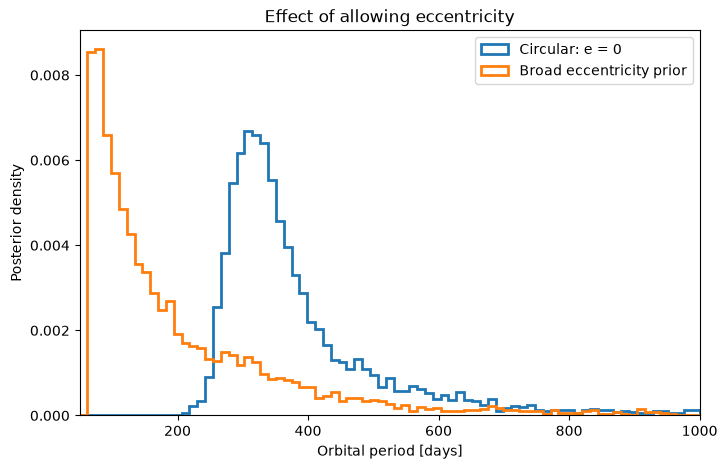

In [44]:
bins = np.linspace(50, 1000, 80)

plt.figure(figsize=(8, 5))

plt.hist(
    period_circular,
    bins=bins,
    density=True,
    histtype="step",
    linewidth=2,
    label="Circular: e = 0"
)

plt.hist(
    period_eccentric,
    bins=bins,
    density=True,
    histtype="step",
    linewidth=2,
    label="Broad eccentricity prior"
)

plt.xlabel("Orbital period [days]")
plt.ylabel("Posterior density")
plt.title("Effect of allowing eccentricity")
plt.xlim(50, 1000)
plt.legend()
plt.show()

In [45]:
np.save(
    "../data/posterior_eccentric_uniform.npy",
    flat_samples
)